# Phase 3, Notebook 15: Complete workflow, evidence dashboard and walkthroughs

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 11 to 15 (all five tasks)  
**Objective:** Show that every Phase 3 deliverable exists, agrees with the executed notebooks, and works end to end for one concrete case per task, using the full 38-stage workflow of Phase 1 and 2.  
**Workflow stages covered in this notebook:** 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3 | seed: 42


This notebook **recomputes nothing heavy**. It reads the artifacts the task notebooks wrote (models, tables, figures), checks them, and walks one example through each task. Run notebooks 01 to 14 first (`python scripts/execute_notebooks.py`).

## Part 1: The 38-stage workflow for all of Phase 3 (Tasks 11 to 15)

Each stage below covers the five tasks together, using the same stage names as Phase 1 and Phase 2. The detailed per-task work is in notebooks 01 to 14; this notebook re-reads their saved results so one notebook shows the whole workflow from business question to conclusion. Part 2 (Appendix A to G) keeps the artifact checks and the one-case walkthroughs.

## Stage 1: Business Understanding

*What this stage is for:* Who needs this result and what decision it supports.

Five decisions are supported in Phase 3. All outputs are advice for a human, never an automatic decision.

In [2]:
biz = pd.DataFrame([
 ('11 Resume ranking', 'Recruiters with hundreds of resumes per opening', 'Which candidates to read first for a job'),
 ('12 Fairness audit', 'HR leadership, legal, candidates', 'Whether the screener treats identical candidates identically'),
 ('13 Attrition model v2', 'HR business partners', 'Which employees may need an earlier conversation'),
 ('14 Risk explanations', 'Managers and HR', 'What to talk about with each of the 430 active employees'),
 ('15 Pay bands', 'Hiring managers and compensation team', 'A fair offer range for a new hire')], columns=['task', 'who needs the result', 'decision it supports'])
biz

                    task                             who needs the result                                          decision it supports
0      11 Resume ranking  Recruiters with hundreds of resumes per opening                      Which candidates to read first for a job
1      12 Fairness audit                 HR leadership, legal, candidates  Whether the screener treats identical candidates identically
2  13 Attrition model v2                             HR business partners              Which employees may need an earlier conversation
3   14 Risk explanations                                  Managers and HR      What to talk about with each of the 430 active employees
4           15 Pay bands            Hiring managers and compensation team                             A fair offer range for a new hire

## Stage 2: Problem Definition

*What this stage is for:* The exact prediction, ranking or measurement problem, its inputs and its output.

Each task is one precisely stated problem with an input and an output.

In [3]:
prob = pd.DataFrame([
 ('11', 'Rank 185 resumes against each of 10 job descriptions', 'resume text, job text, skills', 'ranked list per job with matched / missing skills', 'ranking'),
 ('12', 'Do 25 twin resumes (one detail changed) get the same score?', 'resume_bias_pairs + screener', 'score gap per pair, before and after a fix', 'measurement'),
 ('13', 'Will an employee leave within 12 months?', '42 columns of the attrition table (as-of date)', 'probability of leaving', 'binary classification'),
 ('14', 'Why does each of 430 active employees get their score?', 'attrition_scoring_2026 + model v2', 'score, band, 3 reasons, review note', 'explanation'),
 ('15', 'What offer range fits a new hire for a role?', 'job-related columns of salary_training', 'low / mid / high band', 'regression + range')], columns=['task', 'question', 'input', 'output', 'type'])
prob

  task                                                     question                                           input                                             output                   type
0   11         Rank 185 resumes against each of 10 job descriptions                   resume text, job text, skills  ranked list per job with matched / missing skills                ranking
1   12  Do 25 twin resumes (one detail changed) get the same score?                    resume_bias_pairs + screener         score gap per pair, before and after a fix            measurement
2   13                     Will an employee leave within 12 months?  42 columns of the attrition table (as-of date)                             probability of leaving  binary classification
3   14       Why does each of 430 active employees get their score?               attrition_scoring_2026 + model v2                score, band, 3 reasons, review note            explanation
4   15                 What offer range fits a new

## Stage 3: Objective and Success Criteria

*What this stage is for:* What number or evidence shows the task is done well, decided before looking at results.

Success criteria were fixed from the task brief before results were read. Where each is measured is listed.

In [4]:
crit = pd.DataFrame([
 ('11', 'Quality reported against human labels; 5 misranks explained; no name, gender, age or college tier in the score', 'reports/task11/'),
 ('12', 'Average twin gap before and after; ranking quality still reported; honest statement', 'reports/task12/'),
 ('13', 'Same folds as Task 3; gain proven or its absence explained; tuning log; versioned model', 'reports/task13/'),
 ('14', '430 rows with score, band, 3 plain-English reasons, sample format, human-review note', 'reports/task14/'),
 ('15', 'Beats the role-average baseline; group gaps measured; output is a range; limits written', 'reports/task15/')], columns=['task', 'success criterion', 'evidence folder'])
crit

  task                                                                                               success criterion  evidence folder
0   11  Quality reported against human labels; 5 misranks explained; no name, gender, age or college tier in the score  reports/task11/
1   12                             Average twin gap before and after; ranking quality still reported; honest statement  reports/task12/
2   13                         Same folds as Task 3; gain proven or its absence explained; tuning log; versioned model  reports/task13/
3   14                            430 rows with score, band, 3 plain-English reasons, sample format, human-review note  reports/task14/
4   15                         Beats the role-average baseline; group gaps measured; output is a range; limits written  reports/task15/

## Stage 4: Dataset Discovery

*What this stage is for:* Which files exist, how they relate, and which are authoritative.

The seven tables Phase 3 uses, and the two restricted files that are used only to measure fairness.

In [5]:
from cortexhr.phase3.common.io import read_csv
import json
used = ['resumes', 'job_descriptions', 'resume_job_labels', 'resume_bias_pairs', 'attrition_dataset', 'attrition_scoring_2026', 'salary_training', 'sample_attrition_risk', 'baseline_benchmarks', 'data_dictionary']
disc = pd.DataFrame([(t, 'task ' + {'resumes': '11-12', 'job_descriptions': '11', 'resume_job_labels': '11', 'resume_bias_pairs': '12', 'attrition_dataset': '13', 'attrition_scoring_2026': '14', 'salary_training': '15', 'sample_attrition_risk': '14', 'baseline_benchmarks': '13', 'data_dictionary': 'all'}[t], (ROOT / '03_Data' / 'csv' / (t + '.csv')).exists()) for t in used], columns=['table', 'used by', 'file present'])
vault = ROOT / '04_Validation_Vault'
print('restricted validation files present locally (names only, used for measurement, never as model inputs):', sorted(p.name[:14] for p in vault.glob('unlock_CX*')) if vault.exists() else 'folder not present')
disc

restricted validation files present locally (names only, used for measurement, never as model inputs): []


                    table     used by  file present
0                 resumes  task 11-12          True
1        job_descriptions     task 11          True
2       resume_job_labels     task 11          True
3       resume_bias_pairs     task 12          True
4       attrition_dataset     task 13          True
5  attrition_scoring_2026     task 14          True
6         salary_training     task 15          True
7   sample_attrition_risk     task 14          True
8     baseline_benchmarks     task 13          True
9         data_dictionary    task all          True

## Stage 5: Data Loading

*What this stage is for:* Load with the project helpers and check the load is complete.

All tables are loaded with the project helper and the expected row counts are checked.

In [6]:
res = read_csv('resumes'); jd = read_csv('job_descriptions'); lab = read_csv('resume_job_labels'); pairs = read_csv('resume_bias_pairs')
att = read_csv('attrition_dataset'); sc = read_csv('attrition_scoring_2026'); sal = read_csv('salary_training'); sample = read_csv('sample_attrition_risk'); dd = read_csv('data_dictionary')
R = {t: P.task_dir(t) for t in (11, 12, 13, 14, 15)}; risk = pd.read_csv(R[14] / 'attrition_risk_2026.csv')
expected = {'resumes': 185, 'job_descriptions': 10, 'resume_job_labels': 555, 'resume_bias_pairs': 25, 'attrition_scoring_2026': 430, 'salary_training': 2934}
got = {'resumes': len(res), 'job_descriptions': len(jd), 'resume_job_labels': len(lab), 'resume_bias_pairs': len(pairs), 'attrition_scoring_2026': len(sc), 'salary_training': len(sal)}
chk = pd.DataFrame({'expected': expected, 'loaded': got}); chk['ok'] = chk.expected == chk.loaded; print('attrition_dataset rows:', len(att)); chk

attrition_dataset rows: 2389


                        expected  loaded    ok
resumes                      185     185  True
job_descriptions              10      10  True
resume_job_labels            555     555  True
resume_bias_pairs             25      25  True
attrition_scoring_2026       430     430  True
salary_training             2934    2934  True

## Stage 6: Dataset Structure and Shape

*What this stage is for:* Rows, columns, keys and grain of each table.

Rows, columns and the key of every table; a key that is not unique would break joins.

In [7]:
T = {'resumes': (res, 'resume_id'), 'job_descriptions': (jd, 'job_id'), 'resume_job_labels': (lab, ['resume_id', 'job_id']), 'resume_bias_pairs': (pairs, 'pair_id'),
     'attrition_dataset': (att, 'row_id'), 'attrition_scoring_2026': (sc, 'employee_id'), 'salary_training': (sal, 'hire_id')}
pd.DataFrame([(k, d.shape[0], d.shape[1], str(key), not d.duplicated(key).any()) for k, (d, key) in T.items()], columns=['table', 'rows', 'columns', 'key', 'key is unique'])

                    table  rows  columns                      key  key is unique
0                 resumes   185       15                resume_id           True
1        job_descriptions    10       11                   job_id           True
2       resume_job_labels   555        7  ['resume_id', 'job_id']           True
3       resume_bias_pairs    25        8                  pair_id           True
4       attrition_dataset  2389       42                   row_id           True
5  attrition_scoring_2026   430       34              employee_id           True
6         salary_training  2934       17                  hire_id           True

## Stage 7: Data Dictionary and Schema Understanding

*What this stage is for:* What each column means, from the supplied dictionary and from inspection.

Meaning of the columns comes from the supplied data dictionary, checked against the real columns.

In [8]:
print('dictionary rows:', len(dd), '| sheets:', dd.sheet.nunique())
focus = ['left_within_12m', 'tenure_months', 'comp_ratio', 'offered_annual_fixed', 'career_gap_months', 'human_suitability_score', 'required_skill_coverage', 'college_tier']
dd[dd.column.isin(focus)][['sheet', 'column', 'data_type', 'description']].drop_duplicates('column').reset_index(drop=True)

dictionary rows: 315 | sheets: 30


               sheet                   column data_type                                                                                              description
0  attrition_dataset            tenure_months   integer                                                            Months since joining at the observation date.
1  attrition_dataset               comp_ratio   decimal                   Pay divided by role mid-point (inflation-adjusted); below 1 means paid under midpoint.
2  attrition_dataset          left_within_12m   integer                                  LABEL: 1 if the employee left within 12 months of the observation date.
3    salary_training        career_gap_months   integer  Months of career break before joining (0 if none). Linked to a planted pay bias; see the AI answer key.
4    salary_training     offered_annual_fixed   integer                                                          TARGET: annual fixed pay offered at hire (INR).
5            resumes             c

## Stage 8: Data Type Inspection

*What this stage is for:* Check every column has the type it should have.

Every column has the type the analysis expects; dates parse.

In [9]:
rows = []
for k, (d, _) in T.items():
    ty = d.dtypes.astype(str).value_counts().to_dict(); rows.append((k, ty))
date_ok = {'attrition observation_date': pd.to_datetime(att.observation_date, errors='coerce').notna().mean(), 'salary hire_date': pd.to_datetime(sal.hire_date, errors='coerce').notna().mean()}
print('share of dates that parse:', {k: round(v, 3) for k, v in date_ok.items()}); pd.DataFrame(rows, columns=['table', 'column types'])

share of dates that parse: {'attrition observation_date': np.float64(1.0), 'salary hire_date': np.float64(1.0)}


                    table                             column types
0                 resumes                {'str': 14, 'float64': 1}
1        job_descriptions                   {'str': 8, 'int64': 3}
2       resume_job_labels     {'str': 4, 'float64': 2, 'int64': 1}
3       resume_bias_pairs                   {'str': 7, 'int64': 1}
4       attrition_dataset  {'float64': 15, 'int64': 14, 'str': 13}
5  attrition_scoring_2026   {'float64': 14, 'int64': 12, 'str': 8}
6         salary_training     {'int64': 8, 'str': 7, 'float64': 2}

## Stage 9: Data Quality Assessment

*What this stage is for:* A one-page quality profile before any modelling.

A one-page quality profile: missing cells, exact duplicate rows and constant columns per table.

In [10]:
rows = []
for k, (d, _) in T.items():
    rows.append((k, round(d.isna().mean().mean() * 100, 2), int(d.duplicated().sum()), [c for c in d.columns if d[c].nunique(dropna=False) <= 1]))
pd.DataFrame(rows, columns=['table', 'missing cells %', 'duplicate rows', 'constant columns'])

                    table  missing cells %  duplicate rows                                                                  constant columns
0                 resumes             4.11               0                                                                                []
1        job_descriptions             0.00               0                                                                   [work_location]
2       resume_job_labels             0.00               0                                                                                []
3       resume_bias_pairs             0.00               0  [skills_identical, experience_identical, expected_score_difference, instruction]
4       attrition_dataset            12.63               0                                                                                []
5  attrition_scoring_2026             4.51               0                                                                [observation_date]
6         sal

## Stage 10: Missing Value Analysis

*What this stage is for:* Where values are missing, how much, and why that may be.

Where values are missing and why. Missing exit information for people who stayed is by design, and it is exactly the leakage Task 13 excludes.

In [11]:
miss = pd.concat({k: d.isna().mean().mul(100).round(1)[lambda s: s > 0].sort_values(ascending=False).head(4) for k, (d, _) in T.items()}).rename('missing %')
stay = att[att.left_within_12m == 0]; left = att[att.left_within_12m == 1]
print('exit_date missing: stayers %.1f%% | leavers %.1f%%  (by design: only leavers have an exit)' % (stay.exit_date.isna().mean() * 100, left.exit_date.isna().mean() * 100)); miss.to_frame()

exit_date missing: stayers 100.0% | leavers 0.0%  (by design: only leavers have an exit)


                                                    missing %
resumes                certifications                    61.6
attrition_dataset      resignation_date                  86.6
                       exit_date                         85.4
                       exit_reason                       85.4
                       fnf_settlement_amount             85.4
attrition_scoring_2026 months_since_last_promotion       91.4
                       last_performance_rating           22.6
                       last_raise_pct                    22.3
                       last_engagement_score             17.0

## Stage 11: Duplicate Analysis

*What this stage is for:* Exact and near duplicates of rows, keys and texts.

Exact and key duplicates, including identical resume texts, which would inflate ranking quality.

In [12]:
dup = pd.DataFrame([
 ('resumes: resume_id', int(res.resume_id.duplicated().sum())), ('resumes: identical resume_text', int(res.resume_text.duplicated().sum())),
 ('labels: (resume_id, job_id)', int(lab.duplicated(['resume_id', 'job_id']).sum())), ('attrition: (employee_id, observation_date)', int(att.duplicated(['employee_id', 'observation_date']).sum())),
 ('scoring: employee_id', int(sc.employee_id.duplicated().sum())), ('salary: hire_id', int(sal.hire_id.duplicated().sum()))], columns=['check', 'duplicates'])
from cortexhr.data_loading import prepare_attrition, clean_raw
att_clean, dlog = prepare_attrition(att); print('handling (project cleaning step, same in training and scoring): exact duplicate snapshots ignoring row_id ->', dlog)
print('duplicate (employee, date) keys after cleaning:', int(att_clean.duplicated(['employee_id', 'observation_date']).sum())); dup

handling (project cleaning step, same in training and scoring): exact duplicate snapshots ignoring row_id -> {'rows_before': 2389, 'exact_duplicates_dropped': 6, 'rows_after': 2383}
duplicate (employee, date) keys after cleaning: 0


                                        check  duplicates
0                          resumes: resume_id           0
1              resumes: identical resume_text           0
2                 labels: (resume_id, job_id)           0
3  attrition: (employee_id, observation_date)           6
4                        scoring: employee_id           0
5                             salary: hire_id           0

## Stage 12: Outlier Detection and Investigation

*What this stage is for:* Unusual values: are they errors or real?

Unusual values by the 1.5 x IQR rule. They are inspected, not deleted: salaries and experience are real, skewed quantities.

                    variable     n  IQR outliers       min    median         max
0  resume experience (years)   185             0       0.0       3.0         9.3
1            tenure (months)  2389            74      -5.0      31.0       164.0
2      annual fixed pay (Rs)  2389            94  148848.0  757488.0  18671760.0
3        offered salary (Rs)  2934           134  114432.0  624192.0   4197972.0

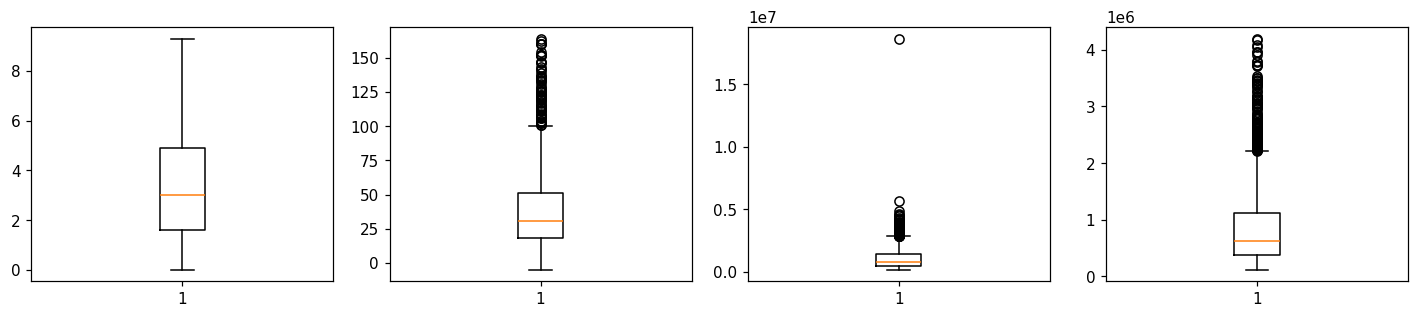

In [13]:
cols = [('resume experience (years)', res.total_experience_years), ('tenure (months)', att.tenure_months), ('annual fixed pay (Rs)', att.annual_fixed_pay), ('offered salary (Rs)', sal.offered_annual_fixed)]
def iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())
out = pd.DataFrame([(a, len(s), iqr(s), round(s.min(), 1), round(s.median(), 1), round(s.max(), 1)) for a, s in cols], columns=['variable', 'n', 'IQR outliers', 'min', 'median', 'max'])
fig, ax = plt.subplots(1, 4, figsize=(13, 3)); [ax[i].boxplot(s.dropna(), vert=True) or ax[i].set_title(a, fontsize=9) for i, (a, s) in enumerate(cols)]; plt.tight_layout(); out

## Stage 13: Invalid and Inconsistent Value Detection

*What this stage is for:* Impossible values, broken links between tables, label contradictions.

Impossible values and broken links between tables.

In [14]:
bad = pd.DataFrame([
 ('resume experience < 0 or > 45 years', int(((res.total_experience_years < 0) | (res.total_experience_years > 45)).sum())),
 ('attrition tenure_months < 0', int((att.tenure_months < 0).sum())), ('attrition comp_ratio <= 0', int((att.comp_ratio <= 0).sum())),
 ('salary offered <= 0', int((sal.offered_annual_fixed <= 0).sum())), ('salary career_gap_months < 0', int((sal.career_gap_months < 0).sum())),
 ('labels pointing to unknown resume', int((~lab.resume_id.isin(res.resume_id)).sum())), ('labels pointing to unknown job', int((~lab.job_id.isin(jd.job_id)).sum())),
 ('twin pairs pointing to unknown resume', int((~pairs.resume_id_original.isin(res.resume_id)).sum() + (~pairs.resume_id_twin.isin(res.resume_id)).sum())),
 ('scoring rows whose employee is missing in risk report', int((~sc.employee_id.isin(risk.employee_id)).sum()))], columns=['rule', 'violations'])
c = clean_raw(att); print('handling: clean_raw turns impossible tenure into missing (then imputed inside each fold). negative tenure before: %d, after: %d (now missing: %d)' % ((att.tenure_months < 0).sum(), (c.tenure_months.dropna() < 0).sum(), int(c.tenure_months.isna().sum() - att.tenure_months.isna().sum())))
print('human score range:', lab.human_suitability_score.min(), 'to', lab.human_suitability_score.max()); bad

handling: clean_raw turns impossible tenure into missing (then imputed inside each fold). negative tenure before: 4, after: 0 (now missing: 4)
human score range: 1 to 5


                                                    rule  violations
0                    resume experience < 0 or > 45 years           0
1                            attrition tenure_months < 0           4
2                              attrition comp_ratio <= 0           0
3                                    salary offered <= 0           0
4                           salary career_gap_months < 0           0
5                      labels pointing to unknown resume           0
6                         labels pointing to unknown job           0
7                  twin pairs pointing to unknown resume           0
8  scoring rows whose employee is missing in risk report           0

## Stage 14: Exploratory Data Analysis (EDA)

*What this stage is for:* Look at the data before modelling.

Look at the data before trusting any model.

four distributions drawn


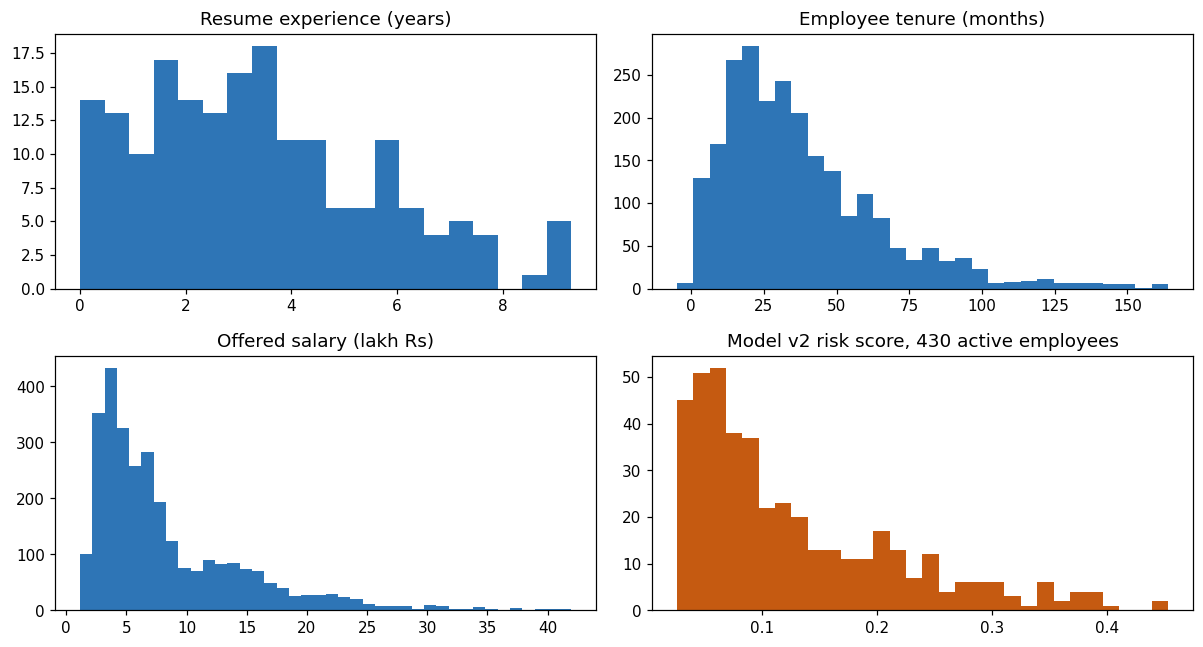

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
ax[0, 0].hist(res.total_experience_years, bins=20, color='#2e75b6'); ax[0, 0].set_title('Resume experience (years)')
ax[0, 1].hist(att.tenure_months, bins=30, color='#2e75b6'); ax[0, 1].set_title('Employee tenure (months)')
ax[1, 0].hist(sal.offered_annual_fixed / 1e5, bins=40, color='#2e75b6'); ax[1, 0].set_title('Offered salary (lakh Rs)')
ax[1, 1].hist(risk.risk_score_12m, bins=30, color='#c55a11'); ax[1, 1].set_title('Model v2 risk score, 430 active employees'); plt.tight_layout(); print('four distributions drawn')

## Stage 15: Univariate Analysis

*What this stage is for:* One variable at a time.

One variable at a time, across the tasks.

In [16]:
pd.concat({'resume experience': res.total_experience_years.describe(), 'tenure months': att.tenure_months.describe(), 'comp ratio': att.comp_ratio.describe(), 'offered salary': sal.offered_annual_fixed.describe(), 'human score': lab.human_suitability_score.describe(), 'risk score 2026': risk.risk_score_12m.describe()}, axis=1).round(2)

       resume experience  tenure months  comp ratio  offered salary  human score  risk score 2026
count             185.00        2389.00     2389.00         2934.00       555.00           430.00
mean                3.37          37.78        1.03       834428.05         2.34             0.13
std                 2.24          27.43        0.14       641315.38         1.06             0.09
min                 0.00          -5.00        0.42       114432.00         1.00             0.03
25%                 1.60          18.00        0.95       380541.00         2.00             0.06
50%                 3.00          31.00        1.03       624192.00         2.00             0.10
75%                 4.90          51.00        1.12      1114299.00         3.00             0.18
max                 9.30         164.00        1.69      4197972.00         5.00             0.45

## Stage 16: Bivariate Analysis

*What this stage is for:* Two variables together, especially against the target or label.

Two variables together: each against the label it is meant to predict.

corr(human score, required skill coverage) = 0.898


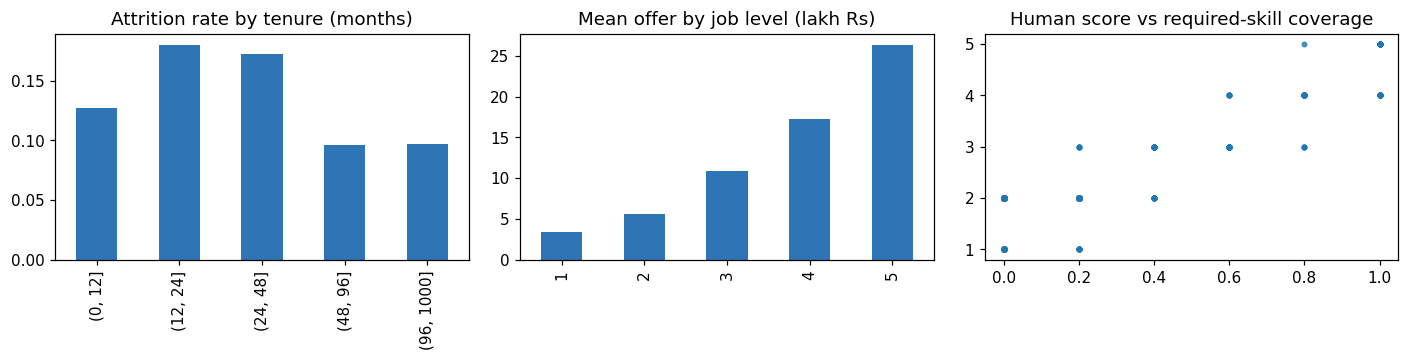

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
att.assign(b=pd.cut(att.tenure_months, [0, 12, 24, 48, 96, 1000])).groupby('b', observed=True).left_within_12m.mean().plot.bar(ax=ax[0], color='#2e75b6'); ax[0].set_title('Attrition rate by tenure (months)'); ax[0].set_xlabel('')
sal.groupby('job_level').offered_annual_fixed.mean().div(1e5).plot.bar(ax=ax[1], color='#2e75b6'); ax[1].set_title('Mean offer by job level (lakh Rs)'); ax[1].set_xlabel('')
ax[2].scatter(lab.required_skill_coverage, lab.human_suitability_score, s=8, alpha=.5); ax[2].set_title('Human score vs required-skill coverage'); plt.tight_layout()
print('corr(human score, required skill coverage) = %.3f' % lab.human_suitability_score.corr(lab.required_skill_coverage))

## Stage 17: Multivariate Analysis

*What this stage is for:* Several variables together: correlation, interaction, redundancy.

Several variables together: correlation among the salary inputs shows which ones carry overlapping information.

                        band_mid_2026  prior_experience_years  career_gap_months  skills_count  market_index  offered_annual_fixed
band_mid_2026                    1.00                    0.79              -0.01          0.33          0.02                  0.96
prior_experience_years           0.79                    1.00              -0.01          0.35          0.03                  0.77
career_gap_months               -0.01                   -0.01               1.00          0.01          0.02                 -0.02
skills_count                     0.33                    0.35               0.01          1.00          0.00                  0.32
market_index                     0.02                    0.03               0.02          0.00          1.00                  0.20
offered_annual_fixed             0.96                    0.77              -0.02          0.32          0.20                  1.00

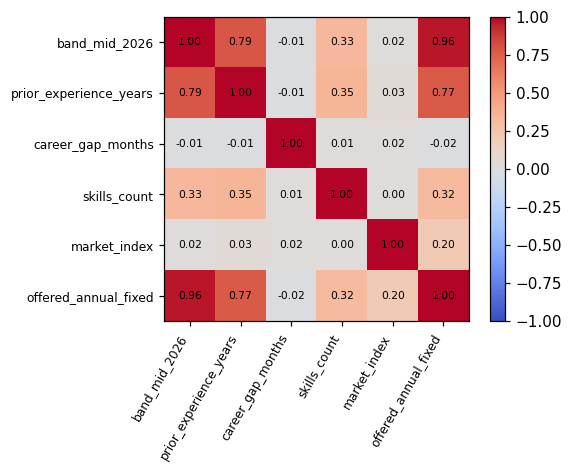

In [18]:
num = sal[['band_mid_2026', 'prior_experience_years', 'career_gap_months', 'skills_count', 'market_index', 'offered_annual_fixed']]; cm = num.corr()
fig, ax = plt.subplots(figsize=(5.5, 4.4)); im = ax.imshow(cm, cmap='coolwarm', vmin=-1, vmax=1); ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=60, ha='right', fontsize=8); ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns, fontsize=8)
[ax.text(j, i, '%.2f' % cm.iloc[i, j], ha='center', va='center', fontsize=7) for i in range(len(cm)) for j in range(len(cm))]; plt.colorbar(im); plt.tight_layout(); cm.round(2)

## Stage 18: Target or Label Analysis

*What this stage is for:* How the target or human label is distributed and how reliable it is.

The label of each task: how it is distributed and how reliable it is.

In [19]:
lab_tab = pd.DataFrame([
 ('attrition left_within_12m', 'share = 1', round(att.left_within_12m.mean(), 3)), ('attrition voluntary_left_within_12m', 'share = 1', round(att.voluntary_left_within_12m.mean(), 3)),
 ('resume shortlist (human)', 'share = Y', round((lab.shortlist == 'Y').mean(), 3)), ('human suitability score', 'mean', round(lab.human_suitability_score.mean(), 2)),
 ('offered salary', 'mean / median (right-skewed)', '%.0f / %.0f' % (sal.offered_annual_fixed.mean(), sal.offered_annual_fixed.median()))], columns=['label', 'statistic', 'value']); lab_tab

                                 label                     statistic            value
0            attrition left_within_12m                     share = 1            0.146
1  attrition voluntary_left_within_12m                     share = 1            0.134
2             resume shortlist (human)                     share = Y            0.171
3              human suitability score                          mean             2.34
4                       offered salary  mean / median (right-skewed)  834428 / 624192

## Stage 19: Data Leakage Investigation

*What this stage is for:* Anything that carries the answer or protected information into the model.

Anything that carries the answer or protected information into a model is excluded and checked here with an assertion.

In [20]:
am = json.load(open(P.METADATA / 'attrition_v2_metadata.json')); sm = json.load(open(P.METADATA / 'salary_band_v1_metadata.json')); rm = json.load(open(P.METADATA / 'resume_ranker_v2_metadata.json'))
leak = set(am['excluded_as_inputs']) & set(am['features_raw']); prot = set(sm['never_inputs']) & set(sm['features'])
assert not leak and not prot, (leak, prot)
print('attrition: excluded as inputs ->', am['excluded_as_inputs']); print('salary never inputs ->', sm['never_inputs']); print('resume ranker never used ->', rm['never_used'])
print('overlap between excluded and used inputs: attrition', leak or 'none', '| salary', prot or 'none')

attrition: excluded as inputs -> ['left_within_12m', 'row_id', 'employee_id', 'observation_date', 'exit_date', 'resignation_date', 'exit_reason', 'exit_interview_done', 'fnf_settlement_amount', 'voluntary_left_within_12m', 'source']
salary never inputs -> ['hire_id', 'hire_date', 'source', 'gender', 'age_years', 'age_band', 'offered_annual_fixed']
resume ranker never used -> ['candidate_name', 'email', 'gender', 'age', 'college_tier', 'city', 'target_job_family']
overlap between excluded and used inputs: attrition none | salary none


## Stage 20: Feature Engineering

*What this stage is for:* Build the inputs the model will use from the raw data.

The inputs each model really uses, built from the raw data.

In [21]:
print('resume score inputs:', rm['score_inputs']); print('attrition raw features:', len(am['features_raw']), '| preprocessing:', am['preprocessing'])
print('salary features (%d): %s' % (len(sm['features']), sm['features']))

resume score inputs: ['resume_text (identifiers masked)', 'job_title', 'required_skills', 'nice_to_have_skills', 'education_preference', 'description_text', 'min_experience_years']
attrition raw features: 43 | preprocessing: cortexhr.features.build_pipeline(include_monthly=True) refit inside every fold and inside the final fit
salary features (9): ['job_level', 'log_band_mid', 'log_market_index', 'prior_experience_years', 'skills_count', 'department_id', 'role_id', 'work_location', 'highest_education']


## Stage 21: Feature Selection and Relevance Analysis

*What this stage is for:* Which inputs are allowed, which are relevant, which must never be used.

Which inputs matter. Permutation importance on the attrition model (drop in ROC-AUC when a column is shuffled).

                   feature  auc_drop      sd
0    last_engagement_score    0.0644  0.0137
1  months_since_last_raise    0.0560  0.0091
2         annual_fixed_pay    0.0310  0.0124
3      manager_changes_12m    0.0306  0.0051
4   total_experience_years    0.0261  0.0083
5               comp_ratio    0.0237  0.0048
6  last_performance_rating    0.0211  0.0078
7            department_id    0.0154  0.0040
8                  role_id    0.0140  0.0141
9      commute_distance_km    0.0132  0.0037

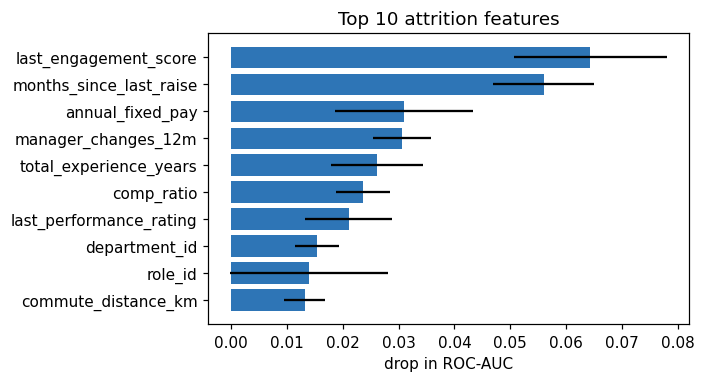

In [22]:
pi = pd.read_csv(R[13] / 'permutation_importance.csv').sort_values('auc_drop', ascending=False).head(10)
fig, ax = plt.subplots(figsize=(6.5, 3.6)); ax.barh(pi.feature[::-1], pi.auc_drop[::-1], xerr=pi.sd[::-1], color='#2e75b6'); ax.set_xlabel('drop in ROC-AUC'); ax.set_title('Top 10 attrition features'); plt.tight_layout(); pi.round(4)

## Stage 22: Data Preprocessing

*What this stage is for:* Cleaning and encoding, fitted on training data only.

Cleaning and encoding are fitted on training data only, inside every fold, so no information leaks from the test part.

In [23]:
print('attrition:', am['preprocessing']); print('attrition note:', am['note'][:300]); print('salary note:', sm['note'][:300])

attrition: cortexhr.features.build_pipeline(include_monthly=True) refit inside every fold and inside the final fit
attrition note: Test-set metrics come from the model fitted on the training part only; attrition_v2.joblib is refit on all labelled rows for scoring.
salary note: Advice for a manager and HR, never an offer. The target is historical offers and may contain past bias.


## Stage 23: Train, Validation and Test Strategy

*What this stage is for:* How data is split so no result is measured on data the model has seen.

How data was split so no result is measured on data the model has seen.

In [24]:
print('attrition: train rows', am['train_rows'], '| test rows', am['test_rows'], '| production refit rows', am['production_fit_rows'], '|', am['cv'], '| seed', am['seed'])
print('salary: train rows', sm['train_rows'], '| test rows', sm['test_rows'], '| production refit rows', sm['production_fit_rows'], '| seed', sm['seed'])
print('resume ranking: no training. The engine is rule based, scored on the human-labelled pool; weights chosen from', len(pd.read_csv(R[11] / 'weight_experiments.csv')), 'logged experiments')

attrition: train rows 1906 | test rows 477 | production refit rows 2383 | StratifiedKFold(5, shuffle, seed 42) on the 80% training part (identical to Task 3) | seed 42
salary: train rows 2347 | test rows 587 | production refit rows 2934 | seed 42
resume ranking: no training. The engine is rule based, scored on the human-labelled pool; weights chosen from 286 logged experiments


## Stage 24: Baseline Establishment

*What this stage is for:* The simple method every model must beat.

The simple method every model must beat, per task.

In [25]:
q = pd.read_csv(R[11] / 'ranking_quality_summary.csv').set_index('engine'); cv = pd.read_csv(R[13] / 'cv_summary.csv').set_index('model'); sm_t = pd.read_csv(R[15] / 'test_metrics.csv').set_index('model')
base = pd.DataFrame([('11', 'random ordering', 'precision@5 %.3f, NDCG@5 %.3f' % tuple(q.loc['random ordering', ['precision@5', 'ndcg@5']])),
 ('13', cv.index[cv.index.str.contains('baseline')][0], 'CV ROC-AUC %.3f' % cv[cv.index.str.contains('baseline')].roc_auc_mean.iloc[0]),
 ('15', sm_t.index[0], 'test MAE Rs %.0f, R2 %.3f' % (sm_t.MAE_rupees.iloc[0], sm_t.R2.iloc[0]))], columns=['task', 'baseline', 'its score']); base

  task                                   baseline                        its score
0   11                            random ordering  precision@5 0.166, NDCG@5 0.266
1   13  Logistic Regression (balanced) [baseline]                 CV ROC-AUC 0.709
2   15   baseline: average offered salary by role     test MAE Rs 115094, R2 0.933

## Stage 25: Model Selection and Justification

*What this stage is for:* Why these candidate methods.

Why these candidates: a transparent one first, then a stronger one, so any gain can be measured against something simple.

In [26]:
print('Task 11 engines:', list(q.index)); print('Task 13 models:', list(cv.index)); print('Task 15 models:', list(sm_t.index))
lgb = pd.read_csv(R[13] / 'lightgbm_cv_summary.csv'); print('Task 13 separate LightGBM challenger rows:', len(lgb))

Task 11 engines: ['final engine (v2, masked)', 'random ordering']
Task 13 models: ['HistGradientBoosting default', 'HistGradientBoosting tuned', 'Logistic Regression (balanced) [baseline]', 'Random Forest (300, balanced) [baseline]', 'attrition-v2 candidate: LR + tuned HGB blend']
Task 15 models: ['baseline: average offered salary by role', 'baseline 2: role average adjusted for market index', 'Ridge regression (job-related features)', 'Gradient boosting (job-related features, tuned)', 'Ridge regression + career_gap_months', 'Gradient boosting + career_gap_months']
Task 13 separate LightGBM challenger rows: 3


## Stage 26: Model Training

*What this stage is for:* Fit the candidates.

Fit the candidates. Parameters and weights that were actually used are printed from the saved metadata.

In [27]:
print('attrition HistGradientBoosting params:', am['hgb_params']); print('resume score weights:', rm['weights']); print('salary final model:', sm['model'], '| band multipliers (log):', sm['band_multipliers_log'])

attrition HistGradientBoosting params: {'learning_rate': 0.05, 'max_iter': 150, 'max_depth': 2, 'max_leaf_nodes': 4, 'min_samples_leaf': 40, 'l2_regularization': 1.0}
resume score weights: {'tfidf': 0.3, 'required_skill': 0.4, 'nice_skill': 0.1, 'experience': 0.2}
salary final model: Ridge regression (job-related features) | band multipliers (log): {'low': -0.1079854165011379, 'mid': 0.0, 'high': 0.10192508943375349}


## Stage 27: Cross-Validation

*What this stage is for:* Repeat the evaluation on several splits to see the spread.

Repeat the evaluation on several splits to see the spread, not only one lucky number.

salary CV (5 folds) is stored in metadata: ['baseline: average offered salary by role', 'baseline 2: role average adjusted for market index', 'Ridge regression (job-related features)'] ...


                                              roc_auc_mean  roc_auc_sd  pr_auc_mean  brier_mean
model                                                                                          
HistGradientBoosting default                        0.6798      0.0170       0.2938      0.1791
HistGradientBoosting tuned                          0.6948      0.0209       0.3099      0.1978
Logistic Regression (balanced) [baseline]           0.7095      0.0209       0.3245      0.2000
Random Forest (300, balanced) [baseline]            0.7000      0.0255       0.3162      0.1233
attrition-v2 candidate: LR + tuned HGB blend        0.7165      0.0171       0.3250      0.1895

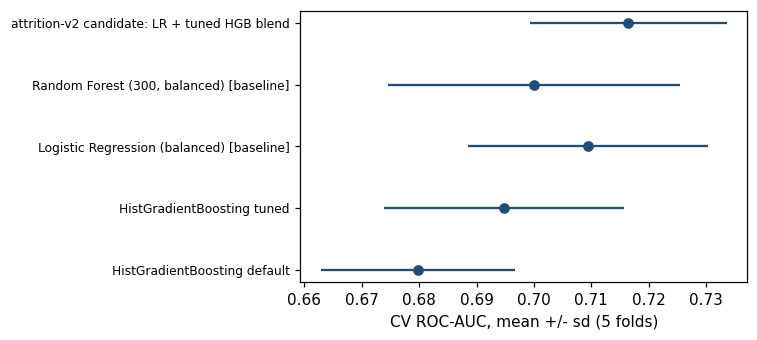

In [28]:
fig, ax = plt.subplots(figsize=(7, 3.2)); ax.errorbar(cv.roc_auc_mean, range(len(cv)), xerr=cv.roc_auc_sd, fmt='o', color='#1f4e79'); ax.set_yticks(range(len(cv))); ax.set_yticklabels([m[:45] for m in cv.index], fontsize=8); ax.set_xlabel('CV ROC-AUC, mean +/- sd (5 folds)'); plt.tight_layout()
print('salary CV (5 folds) is stored in metadata:', list(sm['cv_metrics'].keys())[:3], '...'); cv[['roc_auc_mean', 'roc_auc_sd', 'pr_auc_mean', 'brier_mean']].round(4)

## Stage 28: Hyperparameter Tuning

*What this stage is for:* A small, logged search; no tuning on the test set.

A small, logged search. Nothing is tuned on the test set; every experiment and the decision about it is kept.

In [29]:
t13 = pd.read_csv(R[13] / 'tuning_log.csv'); t15 = pd.read_csv(R[15] / 'tuning_log.csv'); wx = pd.read_csv(R[11] / 'weight_experiments.csv')
print('Task 11 weight experiments:', len(wx), '| Task 13 tuning log:', len(t13), '| Task 13 LightGBM log:', len(pd.read_csv(R[13] / 'lightgbm_tuning_log.csv')), '| Task 15 tuning log:', len(t15))
t13[['experiment_id', 'model', 'roc_auc_mean', 'roc_auc_sd', 'decision']].round(4)

Task 11 weight experiments: 286 | Task 13 tuning log: 12 | Task 13 LightGBM log: 3 | Task 15 tuning log: 6


   experiment_id                 model  roc_auc_mean  roc_auc_sd                           decision
0         HGB-00  HistGradientBoosting        0.6939      0.0222                       not selected
1         HGB-01  HistGradientBoosting        0.6837      0.0185                       not selected
2         HGB-02  HistGradientBoosting        0.6948      0.0209  selected (highest mean CV PR-AUC)
3         HGB-03  HistGradientBoosting        0.6804      0.0167                       not selected
4         HGB-04  HistGradientBoosting        0.6935      0.0146                       not selected
5         HGB-05  HistGradientBoosting        0.6796      0.0206                       not selected
6         HGB-06  HistGradientBoosting        0.6800      0.0161                       not selected
7         HGB-07  HistGradientBoosting        0.6985      0.0172                       not selected
8         HGB-08  HistGradientBoosting        0.6860      0.0156                       not selected


## Stage 29: Model Evaluation

*What this stage is for:* Metrics suited to the problem, against the baseline.

Metrics suited to each problem, against the baseline.

In [30]:
tm = pd.read_csv(R[13] / 'test_metrics.csv')[['model', 'roc_auc', 'pr_auc', 'brier', 'ece', 'recall', 'precision_top10']].round(3)
print('Task 11 ranking quality against human labels'); print(q.round(3).to_string()); print(); print('Task 13 held-out test'); print(tm.to_string()); print(); print('Task 15 test'); print(sm_t.round(3).to_string())

Task 11 ranking quality against human labels
                           precision@5  recall@5  hit_rate@5  ndcg@5    mrr  average_precision  r_precision
engine                                                                                                     
final engine (v2, masked)        0.940     0.549       1.000   0.923  1.000              0.960        0.882
random ordering                  0.166     0.089       0.592   0.266  0.355              0.223        0.168

Task 13 held-out test
                                       model  roc_auc  pr_auc  brier    ece  recall  precision_top10
0  Logistic Regression baseline (calibrated)    0.691   0.355  0.115  0.026   0.443            0.404
1                  attrition-v2 (calibrated)    0.704   0.382  0.113  0.028   0.500            0.447

Task 15 test
                                                    MAE_rupees  RMSE_rupees     R2  median_abs_pct_error  MAE_log
model                                                                

## Stage 30: Error and Misclassification Analysis

*What this stage is for:* Look at the cases the model gets wrong and say why.

Look at the cases the models get wrong and say why.

In [31]:
mis = pd.read_csv(R[11] / 'misranking_analysis.csv'); print('Task 11: five misranked resumes'); print(mis[['job_id', 'resume_id', 'predicted_rank', 'human_score', 'misrank_type', 'root_cause']].to_string(index=False))
c = pd.read_csv(R[13] / 'test_metrics.csv').iloc[-1]; print('\nTask 13 confusion matrix (test): tn %d fp %d fn %d tp %d' % (c.tn, c.fp, c.fn, c.tp))
br = pd.read_csv(R[15] / 'band_recommendations_test.csv'); print('Task 15: actual offers inside the recommended band: %.1f%% of %d' % (br.inside_band.mean() * 100, len(br)))

Task 11: five misranked resumes
job_id resume_id  predicted_rank  human_score                                                             misrank_type                                                                                                                                                                                          root_cause
   J09  RES-0012              20            5 relevant candidate ranked below clearly weaker candidates (under-ranked)                                                                                    Human reviewers valued overall profile more than strict skill coverage; required_coverage pushed the score down.
   J03  RES-0029              34            1    weak candidate ranked above clearly stronger candidates (over-ranked) All candidates around this rank miss most required skills, so the order between them is decided by weak signals (text similarity and experience); the score difference is small (model score 0.19).
   J03  RES-0040       

## Stage 31: Explainability and Feature Importance

*What this stage is for:* What drives the output, in plain words.

What drives the output, in plain words. The 430-row report uses grouped Shapley reasons; the native SHAP library was also run on all 430 employees as a separate comparison.

In [32]:
reasons = pd.concat([risk.top_reason_1, risk.top_reason_2, risk.top_reason_3]).str.split(' \\(').str[0].value_counts().head(8)
print('most frequent reasons across the 430 reports:'); print(reasons.to_string())
sf = R[14] / 'shap_full430_summary.json'; cf = R[14] / 'shap_full430_comparison.csv'
if sf.exists():
    s = json.load(open(sf)); print('\nnative SHAP', s.get('shap_version', '?'), 'on', s.get('rows', '?'), 'employees; additivity error', s.get('additivity_max_error', '?'))
    if cf.exists():
        k = pd.read_csv(cf); print('computed from the per-employee comparison file (%d rows): mean top-3 overlap with the grouped method %.2f | same top reason %.1f%% | all three identical %.1f%%' % (len(k), k.top3_overlap.mean(), k.same_top1.mean() * 100, (k.top3_overlap == 1).mean() * 100))
else: print('\nnative SHAP summary not found: run python scripts/run_shap_full430.py')

most frequent reasons across the 430 reports:
The job level                                                                                                           201
Pay compared with the role's mid-point                                                                                  157
The latest engagement score                                                                                             128
The role the person holds raised the predicted risk; this describes common patterns in the role, not the individual.    126
The number of manager changes in the last 12 months                                                                     106
A short time at the company so far                                                                                       92
The department's attrition rate over the previous 12 months                                                              78
The remote-work pattern                                                               

## Stage 32: Fairness and Bias Evaluation

*What this stage is for:* Gaps between groups, measured with the protected attributes only after the fact.

Gaps between groups, measured with protected attributes only after the fact, never as inputs.

In [33]:
fa = json.load(open(R[12] / 'fairness_results.json')); print('Task 12 mean twin gap %.6f -> %.6f (max %.4f -> %.4f); NDCG@5 %.3f -> %.3f' % (fa['before']['mean_abs_gap'], fa['after']['mean_abs_gap'], fa['before']['max_abs_gap'], fa['after']['max_abs_gap'], fa['quality_before']['ndcg@5'], fa['quality_after']['ndcg@5']))
print('\nTask 13 attrition by gender'); print(pd.read_csv(R[13] / 'group_gender.csv').round(3).to_string(index=False)); print('\nTask 15 pay gaps by gender'); print(pd.read_csv(R[15] / 'gender_gaps.csv').round(4).to_string(index=False))
print('\nEqual accuracy is not equal treatment: a model can be equally accurate for two groups and still treat two individuals differently, so the twin test, not the accuracy table, is the fairness evidence.')

Task 12 mean twin gap 0.000126 -> 0.000000 (max 0.0016 -> 0.0000); NDCG@5 0.926 -> 0.923

Task 13 attrition by gender
gender    n  actual_leave_rate  mean_predicted_risk  flagged_top10_share  recall_of_leavers_in_top10   auc
Female 1011              0.155                0.153                0.097                       0.261 0.705
  Male 1311              0.139                0.155                0.104                       0.275 0.722
 Other   61              0.164                0.153                0.082                       0.300 0.747

Task 15 pay gaps by gender
                                measure  group_gap  mean[Female]  mean[Male]  mean[Other]
actual offer / band mid-point (history)     0.0140        0.9841      0.9979       0.9981
                model A predicted ratio     0.0043        0.9864      0.9907       0.9879
       model B predicted ratio (chosen)     0.0025        0.9885      0.9891       0.9866
               model A actual/predicted     0.0125        0.9979  

## Stage 33: Model Calibration or Prediction Reliability

*What this stage is for:* Are the numbers trustworthy as numbers?

Are the numbers trustworthy as numbers? Calibration of the attrition scores and the spread of the final bands.

In [34]:
cc = pd.read_csv(R[13] / 'calibration_comparison.csv'); print(cc.round(4).to_string(index=False)); print()
print('final report: mean score by band'); risk.groupby('risk_band').risk_score_12m.agg(['count', 'mean', 'min', 'max']).round(3)

  method  brier    ece  roc_auc  pr_auc  mean_probability  base_rate
    none 0.1895 0.2521   0.7170  0.3145            0.3985     0.1464
 sigmoid 0.1144 0.0137   0.7170  0.3081            0.1540     0.1464
isotonic 0.1153 0.0144   0.7132  0.2963            0.1552     0.1464

final report: mean score by band


           count   mean    min    max
risk_band                            
High          43  0.330  0.266  0.453
Low          301  0.076  0.026  0.154
Medium        86  0.204  0.155  0.258

## Stage 34: Model Comparison and Final Selection

*What this stage is for:* Choose on evidence, not on the highest score alone.

Choose on evidence, not on the highest score alone.

In [35]:
print('Task 13 verdict:', am['verdict']['text']); print(); pd.read_csv(R[13] / 'paired_differences.csv').round(4)

Task 13 verdict: Gain is NOT proven: the 95% interval of the paired fold difference includes 0 (or is below it), so the simpler baseline is not beaten.



    metric                                             a                                          b  mean_diff  sd_diff  boot_ci_low  boot_ci_high  folds_a_better  n_folds
0  roc_auc  attrition-v2 candidate: LR + tuned HGB blend  Logistic Regression (balanced) [baseline]     0.0070   0.0115      -0.0022        0.0162               3        5
1   pr_auc  attrition-v2 candidate: LR + tuned HGB blend  Logistic Regression (balanced) [baseline]     0.0005   0.0279      -0.0181        0.0249               2        5
2  roc_auc                    HistGradientBoosting tuned  Logistic Regression (balanced) [baseline]    -0.0147   0.0184      -0.0289       -0.0004               1        5
3   pr_auc                    HistGradientBoosting tuned  Logistic Regression (balanced) [baseline]    -0.0146   0.0599      -0.0523        0.0363               1        5

## Stage 35: Final Prediction Generation

*What this stage is for:* Produce the deliverable.

The deliverables, produced by the saved models.

In [36]:
print('Task 14 risk report rows:', len(risk), '| bands:', risk.risk_band.value_counts().to_dict()); print('Task 15 band recommendations on the test hires:', len(br)); print('Task 11 top-5 lists written:', len(pd.read_csv(R[11] / 'top5_per_job_all_resumes.csv')), 'rows'); risk[['employee_id', 'risk_score_12m', 'risk_band', 'top_reason_1']].head(5)

Task 14 risk report rows: 430 | bands: {'Low': 301, 'Medium': 86, 'High': 43}
Task 15 band recommendations on the test hires: 587
Task 11 top-5 lists written: 50 rows


  employee_id  risk_score_12m risk_band                                                                                  top_reason_1
0    EMP-0002           0.110       Low                         The latest engagement score (2.2 out of 5) raised the predicted risk.
1    EMP-0004           0.067       Low                         The latest engagement score (1.0 out of 5) raised the predicted risk.
2    EMP-0011           0.090       Low                                            The job level (level 1) raised the predicted risk.
3    EMP-0013           0.091       Low  Pay compared with the role's mid-point (0.83 times the mid-point) raised the predicted risk.
4    EMP-0015           0.026       Low  Pay compared with the role's mid-point (0.92 times the mid-point) raised the predicted risk.

## Stage 36: Output and Business Validation

*What this stage is for:* Check the output against the required format and read it as the user would.

The output is checked against the required format and read as the user would read it.

In [37]:
same_cols = list(risk.columns) == list(sample.columns); ex = json.load(open(R[14] / 'explanation_run.json'))
print('columns identical to sample_attrition_risk:', same_cols); print('430 rows, unique employees, all in the scoring file:', len(risk) == 430, risk.employee_id.is_unique, set(risk.employee_id) == set(sc.employee_id))
print('every row carries a human-review note:', bool(risk.model_note.str.contains('review', case=False).all())); print('Task 14 automated checks passed: %d of %d' % (sum(c['passed'] for c in ex['checks']), len(ex['checks'])))
print('\nfirst row read aloud:'); r = risk.iloc[0]; print(r.employee_id, r.risk_band, round(r.risk_score_12m, 3))
for k in (1, 2, 3): print('  -', r['top_reason_%d' % k])

columns identical to sample_attrition_risk: True
430 rows, unique employees, all in the scoring file: True True True
every row carries a human-review note: True
Task 14 automated checks passed: 14 of 14

first row read aloud:
EMP-0002 Low 0.11
  - The latest engagement score (2.2 out of 5) raised the predicted risk.
  - The role the person holds raised the predicted risk; this describes common patterns in the role, not the individual.
  - The attendance pattern over the last 3 months (attendance 96%, 1 unpaid absence days) raised the predicted risk.


## Stage 37: Model Saving, Versioning and Reproducibility

*What this stage is for:* Artifacts, metadata, seeds, environment.

Artifacts, checksums, seeds and the environment each result was produced in.

In [38]:
from cortexhr.phase3.attrition.v2 import file_sha256
rec = {'attrition_v2.joblib': am['artifact_sha256']['attrition_v2.joblib'], 'salary_band_v1.joblib': sm['sha256'], 'resume_ranker_v2.joblib': rm['sha256']}
print(pd.DataFrame([(k, file_sha256(P.MODELS / k) == v) for k, v in rec.items()], columns=['artifact', 'checksum matches metadata']).to_string(index=False))
print('seed:', SEED, '| model versions:', am['model_version'], sm['model_version'], rm['engine_version']); print('environment when attrition-v2 was trained:', am['environment'])

               artifact  checksum matches metadata
    attrition_v2.joblib                       True
  salary_band_v1.joblib                       True
resume_ranker_v2.joblib                       True
seed: 42 | model versions: attrition-v2 salary-band-v1 resume-ranker-v2-masked
environment when attrition-v2 was trained: {'python': '3.12.3', 'scikit-learn': '1.8.0', 'pandas': '3.0.2', 'numpy': '2.4.4', 'scipy': '1.17.1', 'optional_libraries': {'lightgbm': None, 'xgboost': None, 'shap': None}}


## Stage 38: Final Findings, Limitations and Conclusion

*What this stage is for:* What was found, what remains, what must not be done with it.

What was found, what remains and what the work must not be used for.

In [39]:
fin = pd.DataFrame([
 ('11', 'Ranking engine', 'precision@5 %.3f vs random %.3f' % (q.loc[q.index != 'random ordering', 'precision@5'].iloc[0], q.loc['random ordering', 'precision@5'])),
 ('12', 'Fairness audit', 'mean twin gap %.6f -> %.6f; NDCG@5 %.3f -> %.3f' % (fa['before']['mean_abs_gap'], fa['after']['mean_abs_gap'], fa['quality_before']['ndcg@5'], fa['quality_after']['ndcg@5'])),
 ('13', 'Attrition v2', 'gain over baseline: ' + ('proven' if am['verdict']['gain_is_meaningful'] else 'not proven') + ' (paired AUC diff %+.4f)' % am['verdict']['mean_diff']),
 ('14', 'Risk report', '%d employees with score, band, 3 reasons and a review note' % len(risk)),
 ('15', 'Pay bands', 'test MAE Rs %.0f, R2 %.3f; %.1f%% of offers inside the band' % (sm['test_metrics'][sm['model']]['MAE_rupees'], sm['test_metrics'][sm['model']]['R2'], sm['band_coverage_test'] * 100))], columns=['task', 'deliverable', 'finding']); print(fin.to_string(index=False))
print('''
Limitations: the attrition gain is not proven; reasons are drivers, not certainty; the pay target may contain past bias; group fairness measured on the supplied attributes only.
Must not be used for: automatic hiring, firing, promotion or pay decisions. A human reviews every output.''')

task    deliverable                                                      finding
  11 Ranking engine                            precision@5 0.940 vs random 0.166
  12 Fairness audit    mean twin gap 0.000126 -> 0.000000; NDCG@5 0.926 -> 0.923
  13   Attrition v2     gain over baseline: not proven (paired AUC diff +0.0070)
  14    Risk report  430 employees with score, band, 3 reasons and a review note
  15      Pay bands test MAE Rs 53925, R2 0.983; 80.2% of offers inside the band

Limitations: the attrition gain is not proven; reasons are drivers, not certainty; the pay target may contain past bias; group fairness measured on the supplied attributes only.
Must not be used for: automatic hiring, firing, promotion or pay decisions. A human reviews every output.


## Part 2: Appendix. Artifact checks, evidence dashboard and one case per task

## Appendix A. Environment and reproducibility

In [40]:
import json, platform, sklearn, scipy, importlib, joblib
from cortexhr.phase3.attrition.v2 import file_sha256, optional_libs
print({'python': platform.python_version(), 'scikit-learn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__, 'seed': SEED})
print('optional libraries (used automatically when installed, NOT needed for any result here):', optional_libs())
print('config file:', (ROOT / 'config' / 'phase3_config.yaml').relative_to(ROOT))

{'python': '3.14.8', 'scikit-learn': '1.8.0', 'pandas': '3.0.2', 'numpy': '2.4.4', 'seed': 42}
optional libraries (used automatically when installed, NOT needed for any result here): {'lightgbm': '4.7.0', 'xgboost': '3.4.1', 'shap': '0.54.1'}
config file: config\phase3_config.yaml


## Appendix B. Artifact inventory with checksums

In [41]:
rows = []
for name, meta in (('resume_ranker_v2.joblib', 'resume_ranker_v2_metadata.json'), ('attrition_v2.joblib', 'attrition_v2_metadata.json'), ('attrition_v2_train_only.joblib', 'attrition_v2_metadata.json'), ('salary_band_v1.joblib', 'salary_band_v1_metadata.json')):
    m = json.load(open(P.METADATA / meta)); rec = m.get('sha256') or m['artifact_sha256'][name]; rows.append({'artifact': name, 'size_kb': round((P.MODELS / name).stat().st_size / 1024), 'metadata': meta, 'checksum_matches': file_sha256(P.MODELS / name) == rec})
pd.DataFrame(rows)

                         artifact  size_kb                        metadata  checksum_matches
0         resume_ranker_v2.joblib      555  resume_ranker_v2_metadata.json              True
1             attrition_v2.joblib      190      attrition_v2_metadata.json              True
2  attrition_v2_train_only.joblib      188      attrition_v2_metadata.json              True
3           salary_band_v1.joblib        6    salary_band_v1_metadata.json              True

## Appendix C. Evidence dashboard: the headline number of each task, read from the saved files

In [42]:
q = pd.read_csv(P.task_dir(11) / 'ranking_quality_summary.csv').set_index('engine'); fa = json.load(open(P.task_dir(12) / 'fairness_results.json')); cv = pd.read_csv(P.task_dir(13) / 'cv_summary.csv').set_index('model')
v2m = json.load(open(P.METADATA / 'attrition_v2_metadata.json')); risk = pd.read_csv(P.PREDICTIONS / 'attrition_risk_2026.csv'); sm = json.load(open(P.METADATA / 'salary_band_v1_metadata.json')); ex = json.load(open(P.task_dir(14) / 'explanation_run.json'))
dash = pd.DataFrame([
 ('11 resume ranking', 'precision@5 / NDCG@5 / hit rate@5', '%.3f / %.3f / %.3f' % tuple(q.loc['final engine (v2, masked)', ['precision@5', 'ndcg@5', 'hit_rate@5']]), 'random: %.3f / %.3f / %.3f' % tuple(q.loc['random ordering', ['precision@5', 'ndcg@5', 'hit_rate@5']])),
 ('12 fairness audit', 'mean twin gap before -> after', '%.6f -> %.6f' % (fa['before']['mean_abs_gap'], fa['after']['mean_abs_gap']), 'max %.4f -> %.4f; NDCG@5 %.3f -> %.3f' % (fa['before']['max_abs_gap'], fa['after']['max_abs_gap'], fa['quality_before']['ndcg@5'], fa['quality_after']['ndcg@5'])),
 ('13 attrition v2', 'CV ROC-AUC baseline vs v2 blend', '%.3f vs %.3f' % (cv.loc['Logistic Regression (balanced) [baseline]', 'roc_auc_mean'], cv.loc['attrition-v2 candidate: LR + tuned HGB blend', 'roc_auc_mean']), v2m['verdict']['text'][:60] + '...'),
 ('14 risk report', 'rows / bands / format checks', '%d / %s / %d of %d passed' % (len(risk), risk.risk_band.value_counts().to_dict(), sum(c['passed'] for c in ex['checks']), len(ex['checks'])), 'additivity error %.1e' % ex['additivity_max_error']),
 ('15 pay bands', 'test MAE (Rs) / R2 / band coverage', '%.0f / %.3f / %.3f' % (sm['test_metrics'][sm['model']]['MAE_rupees'], sm['test_metrics'][sm['model']]['R2'], sm['band_coverage_test']), 'role-average baseline MAE %.0f' % sm['test_metrics']['baseline: average offered salary by role']['MAE_rupees'])],
 columns=['task', 'measure', 'result', 'reference']); dash

                task                             measure                                                          result                                                        reference
0  11 resume ranking   precision@5 / NDCG@5 / hit rate@5                                           0.940 / 0.923 / 1.000                                    random: 0.166 / 0.266 / 0.592
1  12 fairness audit       mean twin gap before -> after                                            0.000126 -> 0.000000                      max 0.0016 -> 0.0000; NDCG@5 0.926 -> 0.923
2    13 attrition v2     CV ROC-AUC baseline vs v2 blend                                                  0.709 vs 0.716  Gain is NOT proven: the 95% interval of the paired fold diff...
3     14 risk report        rows / bands / format checks  430 / {'Low': 301, 'Medium': 86, 'High': 43} / 14 of 14 passed                                         additivity error 4.4e-16
4       15 pay bands  test MAE (Rs) / R2 / band coverage              

## Appendix D. One walkthrough per task

In [43]:
# Task 11: rank resumes for one job through the API contract
from cortexhr.phase3.resume.api import handle_rank_request
ranker = joblib.load(P.MODELS / 'resume_ranker_v2.joblib'); resp = handle_rank_request({'job_id': 'J05', 'top_k': 3}, ranker)
print('job', resp['job_id'], '| engine', resp['engine_version'], '| never used:', resp['never_used'])
for c in resp['candidates']: print(c['rank'], c['resume_id'], c['score'], c['score_breakdown'], '| missing required:', c['missing_required_skills'])

job J05 | engine resume-ranker-v2-masked | never used: ['candidate_name', 'email', 'gender', 'age', 'college_tier', 'city', 'target_job_family']
1 RES-0068 0.875 {'text_similarity': 1.0, 'required_skill_coverage': 1.0, 'nice_to_have_coverage': 0.75, 'experience_fit': 0.5} | missing required: []
2 RES-0023 0.7946 {'text_similarity': 0.7321, 'required_skill_coverage': 1.0, 'nice_to_have_coverage': 0.75, 'experience_fit': 0.5} | missing required: []
3 RES-0166 0.7946 {'text_similarity': 0.7321, 'required_skill_coverage': 1.0, 'nice_to_have_coverage': 0.75, 'experience_fit': 0.5} | missing required: []


In [44]:
# Task 12: the twin test on one pair
from cortexhr.phase3.common.io import read_csv
pairs = read_csv('resume_bias_pairs'); labels = read_csv('resume_job_labels'); r1 = joblib.load(P.MODELS / 'resume_ranker_v2.joblib'); p = pairs.iloc[0]; job = labels[labels.resume_id == p.resume_id_original].job_id.iloc[0]
a, b = r1.score_pair(p.resume_id_original, job), r1.score_pair(p.resume_id_twin, job); print(p.pair_id, job, '| original score %.6f | twin score %.6f | gap %.6f' % (a['score'], b['score'], b['score'] - a['score']))

BP-01 J01 | original score 0.794121 | twin score 0.794121 | gap 0.000000


In [45]:
# Task 13 and 14: one employee, score + reasons
i = int(risk.risk_score_12m.idxmax()); r = risk.loc[i]; print(r.employee_id, r.risk_band, r.risk_score_12m); [print('  -', r[f'top_reason_{k}']) for k in (1, 2, 3)]; print(r.model_note[:140] + '...')

EMP-0494 High 0.453
  - The working hours and overtime pattern (about 8.7 hours per day, 12.2 overtime hours per month) raised the predicted risk.
  - The department's attrition rate over the previous 12 months (5%) raised the predicted risk; this describes the team, not the individual.
  - The type of employment (Fixed-Term Contract) raised the predicted risk.
Human review required: this is a support signal for HR, not a decision about the person. Bands: High = top 10% of scores, Medium = next 20%....


In [46]:
# Task 15: one band
from cortexhr.phase3.salary import model as S
art = joblib.load(P.MODELS / 'salary_band_v1.joblib'); d = S.load_salary().iloc[[10]]; print(S.recommend_band(art['model'], d, art['band_multipliers'], art['features']).round(0).to_dict('records')[0], '| actual offer', int(d.offered_annual_fixed.iloc[0]))

{'recommended_low': 332000.0, 'recommended_mid': 369800.0, 'recommended_high': 409500.0} | actual offer 462588


## Appendix E. Workflow coverage: the 38 stages per task, counted from the notebooks

In [47]:
import re
NB_ = {11: ['01', '02', '03', '04'], 12: ['05', '06'], 13: ['07', '08', '09'], 14: ['10', '11'], 15: ['12', '13', '14']}; rows = []
for t, pre in NB_.items():
    st, na = set(), set()
    for p_ in pre:
        for c in json.load(open(next((ROOT / 'notebooks').glob(p_ + '_*.ipynb')), encoding='utf-8'))['cells']:
            s = ''.join(c['source']); m = re.match(r'## Stage (\d+):', s) if c['cell_type'] == 'markdown' else None
            if m: st.add(int(m.group(1))); na |= {int(m.group(1))} if 'Not applicable here, and why:' in s else set()
    rows.append({'task': t, 'notebooks': ', '.join(pre), 'stages covered': len(st), 'missing': sorted(set(range(1, 39)) - st) or 'none', 'marked not applicable (with reason)': sorted(na) or 'none'})
pd.DataFrame(rows)

   task       notebooks  stages covered missing marked not applicable (with reason)
0    11  01, 02, 03, 04              38    none                                [26]
1    12          05, 06              38    none                            [25, 26]
2    13      07, 08, 09              38    none                                none
3    14          10, 11              38    none                                none
4    15      12, 13, 14              38    none                                none

## Appendix F. Requirement traceability

In [48]:
tp = ROOT / 'docs' / 'requirements_traceability.csv'
if tp.exists():
    t = pd.read_csv(tp); print(len(t), 'requirements tracked;', t.status.value_counts().to_dict()); print(t.groupby('task').status.value_counts().unstack(fill_value=0).to_string())
else: print('run: python scripts/make_docs.py  (writes docs/requirements_traceability.*)')

51 requirements tracked; {'Complete': 46, 'Complete with documented limitation': 5}
status  Complete  Complete with documented limitation
task                                                 
11            13                                    1
12             8                                    1
13             9                                    1
14             6                                    1
15             6                                    1
all            4                                    0


## Appendix G. Known limitations (honest list)

1. The main attrition-v2 production blend remains LR + HistGradientBoosting; a real LightGBM candidate is separately trained, tuned and evaluated on the same Task 3 folds when installed, and was not a proven improvement. 2. Task 14 reasons for all 430 employees come from the real shap library (PermutationExplainer, shap 0.54.1, 50-row background, 23 HR groups); reasons describe what moved the score, not certainty. 3. The restricted `unlock_CX-12` and `unlock_CX-15` files are used for measurement only and are not committed; they were supplied and validated in the final audit, Task 12 and Task 15 were rerun, and Task 13 group counts were cross-checked while its full retraining rerun exceeded the execution time limit. 4. The attrition v2 gain over the baseline is not proven. 5. Resume ranking evidence rests on 10 jobs and 555 human labels. 6. Pay bands learn from historical offers that may contain past bias.